## EN4554 Assignment 2: CNNs (Task 4 of 4, optional: best CNN under 500k parameters and 20 epochs)


##### **Name:** *Sasanka D.M.I.*  
##### **Index Number:** *220583J*


### Use of AI-Assisted Coding Tools

ChatGPT was used as an AI-assisted tool to review the implementation, identify potential issues, and help interpret the experimental results. The tool provided suggestions for improving code correctness and understanding the effects of different model architectures, optimization strategies, and regularization techniques. The code was reviewed and executed by the student, who is responsible for understanding the implementation, verifying the results, and ensuring the accuracy of the submitted work.

## Setup (same split and normalisation as before; the test set is not loaded until the last cell)

In [1]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)

def set_seed(s=0):
    torch.manual_seed(s); np.random.seed(s); torch.cuda.manual_seed_all(s)
set_seed(0)

full = datasets.CIFAR10('./data', train=True, download=True)
X = torch.tensor(full.data).float().div(255).permute(0, 3, 1, 2)
y = torch.tensor(full.targets)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(0))
tr, va = perm[:45000], perm[45000:]
Xtr, ytr, Xva, yva = X[tr], y[tr], X[va], y[va]

mean = Xtr.mean((0, 2, 3), keepdim=True)      # training statistics only
std  = Xtr.std((0, 2, 3), keepdim=True)
Xtr, Xva = ((Xtr - mean) / std).to(device), ((Xva - mean) / std).to(device)
ytr, yva = ytr.to(device), yva.to(device)
mean, std = mean.to(device), std.to(device)
print(Xtr.shape, Xva.shape)

Using device: cuda
torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32])


## Design
Everything is tuned on the validation split only.
- **Architecture:** CIFAR-style ResNet-20 (3 stages, 3 residual blocks each, batch norm, global average pooling) made **wider** (channels 20/40/80 instead of 16/32/64). Width 20 gives about 0.42M parameters, under the 500k limit. A wider, shallower network trains fast enough for 20 epochs.
- **Training:** SGD with Nesterov momentum 0.9, weight decay 5e-4, one-cycle learning-rate schedule (ramp up, then decay to ~0), batch size 128, 20 epochs.
- **Augmentation:** random flip + random crop (padding 4).
- **Tuning:** the peak learning rate is chosen from {0.05, 0.1, 0.2} using validation accuracy.
- **Ablation:** starting from the final model, change one thing at a time: remove the shortcut, remove augmentation, remove weight decay, use Adam instead of SGD.

In [3]:
def flip_crop(x, pad=4):
    B = x.size(0)
    flip = (torch.rand(B, device=x.device) < 0.5).view(B, 1, 1, 1)
    x = torch.where(flip, x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))
    oy = torch.randint(0, 2 * pad + 1, (B,)).tolist()
    ox = torch.randint(0, 2 * pad + 1, (B,)).tolist()
    return torch.stack([xp[i, :, oy[i]:oy[i] + 32, ox[i]:ox[i] + 32] for i in range(B)])



In [4]:
class Block(nn.Module):
    def __init__(self, c_in, c_out, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.residual, self.stride, self.extra = residual, stride, c_out - c_in

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            sc = x[:, :, ::self.stride, ::self.stride]       # subsample
            sc = F.pad(sc, (0, 0, 0, 0, 0, self.extra))      # zero-pad channels
            out = out + sc
        return F.relu(out)



In [5]:
class Net(nn.Module):
    def __init__(self, n=3, width=20, residual=True):         # depth = 6n + 2
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, width, 3, 1, 1, bias=False), nn.BatchNorm2d(width), nn.ReLU())
        blocks, c_in = [], width
        for c_out, stride in [(width, 1), (2 * width, 2), (4 * width, 2)]:
            for k in range(n):
                blocks.append(Block(c_in, c_out, stride if k == 0 else 1, residual))
                c_in = c_out
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(4 * width, 10)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
    def forward(self, x):
        return self.fc(self.blocks(self.stem(x)).mean((2, 3)))



In [ ]:
def count_params(m):
    return sum(p.numel() for p in m.parameters())

n_params = count_params(Net())
print('parameters:', n_params)


parameters: 420670


In [7]:
@torch.no_grad()
def evaluate(model, X, t):
    model.eval()
    correct = sum((model(X[i:i+1000]).argmax(1) == t[i:i+1000]).sum().item()
                  for i in range(0, len(X), 1000))
    return correct / len(X)


In [8]:
def train(model, epochs=20, max_lr=0.1, wd=5e-4, aug=True, opt_name='sgd', bs=128):
    model = model.to(device)
    if opt_name == 'sgd':
        opt = torch.optim.SGD(model.parameters(), lr=max_lr, momentum=0.9, nesterov=True, weight_decay=wd)
    else:
        opt = torch.optim.Adam(model.parameters(), lr=max_lr, weight_decay=wd)
    steps = (len(Xtr) + bs - 1) // bs                          # batches per epoch
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=max_lr, epochs=epochs, steps_per_epoch=steps)
    hist = dict(train_loss=[], val_acc=[])
    for ep in range(epochs):
        model.train()
        idx = torch.randperm(len(Xtr), device=device)
        total, n = 0.0, 0
        for i in range(0, len(idx), bs):
            b = idx[i:i+bs]
            xb = flip_crop(Xtr[b]) if aug else Xtr[b]
            loss = F.cross_entropy(model(xb), ytr[b])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            total += loss.item() * len(b); n += len(b)
        hist['train_loss'].append(total / n)
        hist['val_acc'].append(evaluate(model, Xva, yva))
        print(f"  epoch {ep+1:2d}  train loss {hist['train_loss'][-1]:.3f}  val acc {hist['val_acc'][-1]:.4f}")
    return model, hist

## Tuning the peak learning rate on the validation split

In [9]:
sweep, best_model, best_val, best_lr = {}, None, 0.0, None

for lr in [0.05, 0.1, 0.2]:
    print('peak lr', lr)
    set_seed(0)
    model, hist = train(Net(), max_lr=lr)
    sweep[lr] = hist
    if hist['val_acc'][-1] > best_val:                         # keep the best model (final-epoch val acc)
        best_model, best_val, best_lr = model, hist['val_acc'][-1], lr

print('\nvalidation accuracy by peak lr:', {lr: h['val_acc'][-1] for lr, h in sweep.items()})
print('best peak lr:', best_lr)

peak lr 0.05
  epoch  1  train loss 1.770  val acc 0.4420
  epoch  2  train loss 1.308  val acc 0.5786
  epoch  3  train loss 1.078  val acc 0.6130
  epoch  4  train loss 0.924  val acc 0.6114
  epoch  5  train loss 0.803  val acc 0.7142
  epoch  6  train loss 0.707  val acc 0.6624
  epoch  7  train loss 0.644  val acc 0.7528
  epoch  8  train loss 0.591  val acc 0.7700
  epoch  9  train loss 0.549  val acc 0.7976
  epoch 10  train loss 0.513  val acc 0.7944
  epoch 11  train loss 0.485  val acc 0.7858
  epoch 12  train loss 0.459  val acc 0.7956
  epoch 13  train loss 0.428  val acc 0.8284
  epoch 14  train loss 0.407  val acc 0.8262
  epoch 15  train loss 0.374  val acc 0.8426
  epoch 16  train loss 0.345  val acc 0.8582
  epoch 17  train loss 0.304  val acc 0.8722
  epoch 18  train loss 0.269  val acc 0.8778
  epoch 19  train loss 0.236  val acc 0.8800
  epoch 20  train loss 0.217  val acc 0.8808
peak lr 0.1
  epoch  1  train loss 1.653  val acc 0.5010
  epoch  2  train loss 1.200  

- Learning rate 0.05: Training loss decreases steadily, but the final validation accuracy is the lowest of the three.
- Learning rate 0.1: Achieves better validation accuracy and lower training loss than 0.05.
- Learning rate 0.2: Achieves the highest final validation accuracy of 90.28%, although its final training loss is slightly higher than that of 0.1.

The validation accuracy fluctuates between some epochs, particularly for learning rates 0.1 and 0.2. This is not necessarily a problem. The model's training loss continues to decrease, and the final validation results improve overall.


## Ablation (one change at a time from the final model)
The final model is the best run from the sweep above, so it is not retrained.

In [10]:
ablations = {                                                  # name -> arguments for the changed run
    'no shortcut (plain)':     dict(model=lambda: Net(residual=False), max_lr=best_lr),
    'no augmentation':         dict(model=lambda: Net(), max_lr=best_lr, aug=False),
    'no weight decay':         dict(model=lambda: Net(), max_lr=best_lr, wd=0.0),
    'Adam instead of SGD':     dict(model=lambda: Net(), max_lr=2e-3, opt_name='adam'),
}
abl = {'final model': sweep[best_lr]}

for name, kw in ablations.items():
    print(name)
    kw = dict(kw)
    make = kw.pop('model')
    set_seed(0)
    _, abl[name] = train(make(), **kw)

print(f"\n{'setting':24s} {'train loss':>10s} {'val acc':>8s} {'change':>8s}")

base = abl['final model']['val_acc'][-1]

for name, h in abl.items():
    print(f"{name:24s} {h['train_loss'][-1]:10.3f} {h['val_acc'][-1]:8.4f} {h['val_acc'][-1] - base:+8.4f}")

no shortcut (plain)
  epoch  1  train loss 1.748  val acc 0.4676
  epoch  2  train loss 1.272  val acc 0.4762
  epoch  3  train loss 1.043  val acc 0.4700
  epoch  4  train loss 0.917  val acc 0.6090
  epoch  5  train loss 0.836  val acc 0.5152
  epoch  6  train loss 0.780  val acc 0.6738
  epoch  7  train loss 0.746  val acc 0.5624
  epoch  8  train loss 0.710  val acc 0.5380
  epoch  9  train loss 0.687  val acc 0.7320
  epoch 10  train loss 0.661  val acc 0.6612
  epoch 11  train loss 0.641  val acc 0.7162
  epoch 12  train loss 0.610  val acc 0.6814
  epoch 13  train loss 0.590  val acc 0.7748
  epoch 14  train loss 0.559  val acc 0.8082
  epoch 15  train loss 0.529  val acc 0.7864
  epoch 16  train loss 0.482  val acc 0.8254
  epoch 17  train loss 0.429  val acc 0.8296
  epoch 18  train loss 0.368  val acc 0.8658
  epoch 19  train loss 0.303  val acc 0.8852
  epoch 20  train loss 0.259  val acc 0.8850
no augmentation
  epoch  1  train loss 1.493  val acc 0.5452
  epoch  2  train l

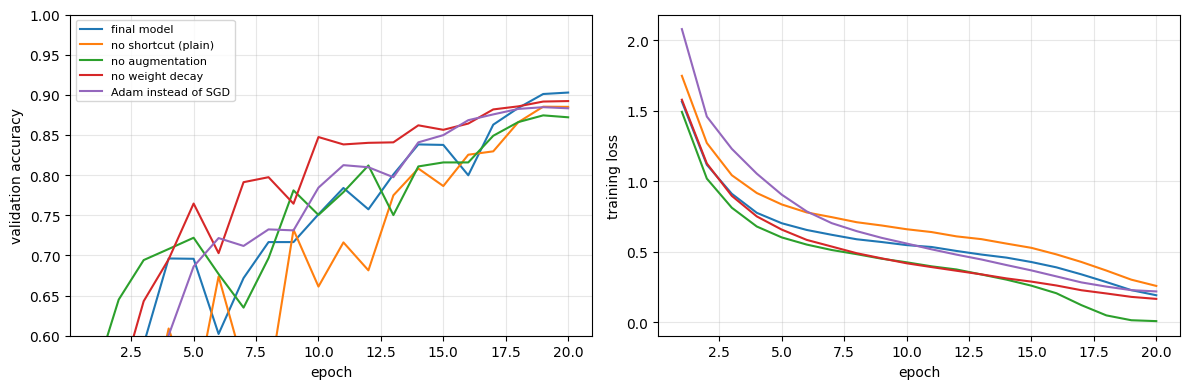

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for name, h in abl.items():
    ep = range(1, len(h['val_acc']) + 1)
    ax[0].plot(ep, h['val_acc'], label=name)
    ax[1].plot(ep, h['train_loss'], label=name)

ax[0].set_ylabel('validation accuracy');
ax[1].set_ylabel('training loss')

for a in ax:
  a.set_xlabel('epoch')
  a.grid(alpha=0.3)

ax[0].legend(fontsize=8);
ax[0].set_ylim(0.6, 1.0)

plt.tight_layout()
plt.show()

### results

| Setting             | Final train loss | Validation accuracy | Change vs. final model |
| ------------------- | ---------------- | ------------------- | ---------------------- |
| Final model         | 0.193            | 90.28%              | Baseline               |
| No shortcut         | 0.259            | 88.50%              | −1.78 pp               |
| No augmentation     | 0.009            | 87.20%              | −3.08 pp               |
| No weight decay     | 0.167            | 89.22%              | −1.06 pp               |
| Adam instead of SGD | 0.220            | 88.32%              | −1.96 pp               |

pp means percentage points.

#### Ablation Study and Discussion

The final residual CNN achieved a validation accuracy of 90.28%, with a final training loss of 0.193. Four ablation experiments were conducted to investigate the contributions of shortcut connections, data augmentation, weight decay, and the optimizer.

**Effect of shortcut connections:** Removing the residual shortcuts reduced validation accuracy from 90.28% to 88.50%, a decrease of 1.78 percentage points. The plain network also had a higher training loss of 0.259. This suggests that residual connections improved optimization and helped the network learn more effectively.

**Effect of data augmentation:** Removing augmentation resulted in the largest validation accuracy decrease, from 90.28% to 87.20%, a reduction of 3.08 percentage points. The training loss fell to 0.009, while validation accuracy remained lower. This indicates substantial overfitting, suggesting that random horizontal flipping and cropping helped the model generalize to unseen images.

**Effect of weight decay:** Removing weight decay reduced validation accuracy to 89.22%, a decrease of 1.06 percentage points. Although the model achieved a lower training loss, its validation performance was worse. This suggests that weight decay provided a useful regularization effect.

**Effect of the optimizer:** Replacing momentum SGD with Adam reduced validation accuracy to 88.32%, a decrease of 1.96 percentage points. Under the selected configurations, SGD with momentum performed better. However, the Adam learning rate was not independently tuned, so this result does not establish that SGD is inherently superior to Adam.

Overall, the observed ranking by validation accuracy drop was data augmentation (3.08 percentage points), optimizer choice (1.96), shortcut connections (1.78), and weight decay (1.06). These results suggest that data augmentation had the largest effect in this experiment. Since each setting was evaluated with one random seed, the ranking should be interpreted as an experimental observation rather than a universal conclusion.


## Final test accuracy
The test set is used here for the first and only time, on the final model chosen with the validation split.

In [12]:
test = datasets.CIFAR10('./data', train=False, download=True)
Xte = torch.tensor(test.data).float().div(255).permute(0, 3, 1, 2).to(device)
Xte = (Xte - mean) / std                                       # training-set statistics
yte = torch.tensor(test.targets).to(device)

test_acc = evaluate(best_model, Xte, yte)
print(f'Final model: {n_params:,} parameters, peak lr {best_lr}, 20 epochs')
print(f'Validation accuracy: {best_val:.4f}')
print(f'TEST accuracy:       {test_acc:.4f}')

Final model: 420,670 parameters, peak lr 0.2, 20 epochs
Validation accuracy: 0.9028
TEST accuracy:       0.9037


The final residual CNN contains 420,670 trainable parameters, satisfying the limit of 500,000 parameters. It uses three stages of convolutional blocks with batch normalization and ReLU activation, residual shortcut connections, global average pooling, and a fully connected output layer. The model was trained for 20 epochs using SGD with momentum, Nesterov acceleration, weight decay, random horizontal flipping and cropping, and a OneCycle learning-rate schedule with a peak learning rate of 0.2.

The final model achieved a validation accuracy of 90.28% and a test accuracy of 90.37%, a difference of only 0.09 percentage points. The close agreement indicates consistent performance on the validation and test sets, with no apparent large generalization gap. The test set was reserved for the final evaluation and was not used for hyperparameter selection.

Final verdict: Task 4 is complete based on the results provided. Your implementation satisfies the stated parameter and epoch limits, includes four ablation experiments, and reports the final test accuracy. Before submitting, ensure that the test evaluation was performed only once in your actual notebook session.